# TP PyTorch, Partie 1 : les bases

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torcheval.metrics import R2Score

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__)
print("Device  :", device)

C:\Users\LOQ\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch : 2.15.0+cpu
Device  : cpu


## 1. Tensors et `device`

In [2]:
# Création : scalaire, vecteur, matrice
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar :", scalar, "| shape =", scalar.shape)
print("vector :", vector, "| shape =", vector.shape)
print("matrix :", matrix, "| shape =", matrix.shape, "| dtype =", matrix.dtype)

# Manipulation
x = torch.arange(12)
x2 = x.reshape(3, 4)
print("\nreshape(3, 4) :\n", x2)
print("colonne 1 :", x2[:, 1])
print("ligne 0   :", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("\nA @ B :\n", A @ B)          # produit matriciel
print("A * B :\n", A * B)            # produit terme à terme
print("mean(A) =", A.mean().item(), "| sum(A) =", A.sum().item())

# Placer un tensor sur le device (CPU ou GPU)
v = vector.to(device)
print("\nv.device =", v.device)

scalar : tensor(3.) | shape = torch.Size([])
vector : tensor([1., 2., 3.]) | shape = torch.Size([3])
matrix : tensor([[1., 2.],
        [3., 4.]]) | shape = torch.Size([2, 2]) | dtype = torch.float32

reshape(3, 4) :
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1 : tensor([1, 5, 9])
ligne 0   : tensor([0, 1, 2, 3])

A @ B :
 tensor([[ 4.,  4.],
        [10.,  8.]])
A * B :
 tensor([[2., 0.],
        [3., 8.]])
mean(A) = 2.5 | sum(A) = 10.0

v.device = cpu


## 2. Autograd : calcul des gradients

On prend $y = wx + b$ et $L = (y - 10)^2$, avec $x = 2$, $w = 3$, $b = 1$.
À la main : $\frac{\partial L}{\partial w} = 2(y-10)\,x$ et $\frac{\partial L}{\partial b} = 2(y-10)$.

In [3]:
# Méthode 1 : loss.backward() remplit .grad sur chaque tensor avec requires_grad=True
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
loss.backward()

print("y =", y.item(), "| loss =", loss.item())
print("dL/dw =", w.grad.item())
print("dL/db =", b.grad.item())

y = 7.0 | loss = 9.0
dL/dw = -12.0
dL/db = -6.0


In [4]:
# Méthode 2 : torch.autograd.grad renvoie les gradients sans toucher à .grad
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2
dw, db = torch.autograd.grad(loss, (w, b))

print("dL/dw =", dw.item(), "| dL/db =", db.item())

# Vérification analytique
y_val = 3.0 * 2.0 + 1.0
print("à la main :", 2 * (y_val - 10) * 2.0, 2 * (y_val - 10))

dL/dw = -12.0 | dL/db = -6.0
à la main : -12.0 -6.0


## 3. Régression linéaire : $y = 3x + 2 + \text{bruit}$

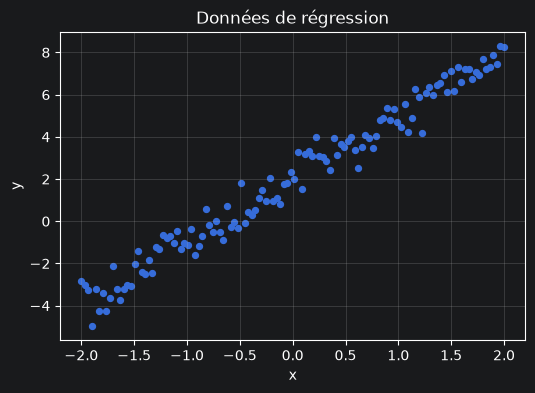

In [5]:
# Données : 120 points entre -2 et 2, avec un bruit gaussien
X = torch.linspace(-2, 2, 120).unsqueeze(1)      # shape (120, 1)
y = 3 * X + 2 + 0.6 * torch.randn_like(X)        # shape (120, 1)

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Données de régression")
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
# Modèle, loss et optimizer
model_reg = nn.Linear(1, 1).to(device)           # y = w*x + b
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

# Données sur le même device que le modèle
X_d, y_d = X.to(device), y.to(device)

losses = []
for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X_d)              # 1. forward
    loss = criterion(y_pred, y_d)        # 2. loss

    optimizer.zero_grad()                # 3. remise à zéro des gradients
    loss.backward()                      # 4. backward
    optimizer.step()                     # 5. mise à jour des paramètres

    losses.append(loss.item())
    if (epoch + 1) % 50 == 0:
        print(f"epoch {epoch + 1:3d} | loss = {loss.item():.4f}")

print(f"\nw appris = {model_reg.weight.item():.3f} (cible 3)")
print(f"b appris = {model_reg.bias.item():.3f} (cible 2)")

epoch  50 | loss = 4.6846
epoch 100 | loss = 0.5542
epoch 150 | loss = 0.3463
epoch 200 | loss = 0.3438
epoch 250 | loss = 0.3438
epoch 300 | loss = 0.3438

w appris = 2.989 (cible 3)
b appris = 2.030 (cible 2)


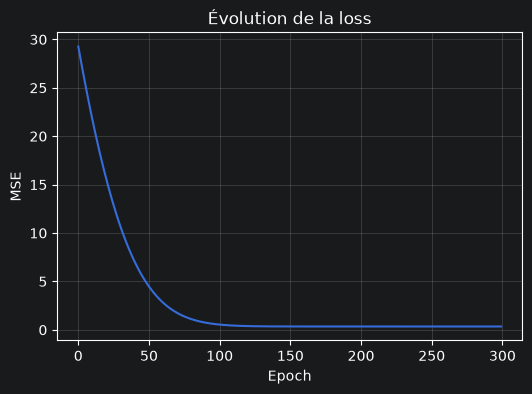

In [7]:
# Évolution de la loss
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Évolution de la loss")
plt.grid(True, alpha=0.3)
plt.show()

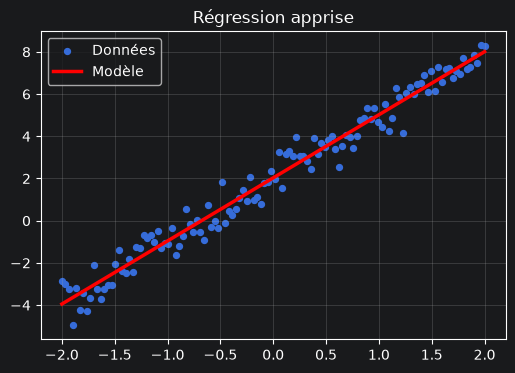

R² = 0.972


In [8]:
# Prédictions en mode évaluation, sans calcul de gradients
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X_d)

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.cpu().numpy(), color="red", linewidth=2.5, label="Modèle")
plt.legend(); plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

# Score R² avec torcheval
metric = R2Score()
metric.update(y_hat.cpu(), y)
print(f"R² = {metric.compute().item():.3f}")

## 4. Construire un réseau avec `nn.Module` et `nn.Sequential`

Deux écritures équivalentes pour un MLP 4 → 16 → 8 → 3.

In [9]:
# Avec nn.Module : on définit les couches dans __init__ et le passage avant dans forward
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3),
        )

    def forward(self, x):
        return self.net(x)

mlp = MLP()
print(mlp)

# Avec nn.Sequential directement
mlp_seq = nn.Sequential(
    nn.Linear(4, 16), nn.ReLU(),
    nn.Linear(16, 8), nn.ReLU(),
    nn.Linear(8, 3),
)

# model(X) appelle model.forward(X)
X_demo = torch.randn(5, 4)
print("\nentrée :", X_demo.shape, "-> sortie :", mlp(X_demo).shape)

n_params = sum(p.numel() for p in mlp.parameters())
print("nombre de paramètres :", n_params)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)

entrée : torch.Size([5, 4]) -> sortie : torch.Size([5, 3])
nombre de paramètres : 243


## 5. Passage à la classification avec `CrossEntropyLoss`

Deux nuages de points en 2D. Le réseau sort des **logits** (scores bruts), sans Softmax :
`CrossEntropyLoss` l'applique en interne. Les étiquettes sont des entiers (`torch.long`).

In [10]:
n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([torch.zeros(n, dtype=torch.long),
                   torch.ones(n, dtype=torch.long)])

model_cls = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 2),                    # 2 classes -> 2 logits
).to(device)

criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

Xc, yc = X_cls.to(device), y_cls.to(device)

losses_cls = []
for epoch in range(250):
    model_cls.train()
    logits = model_cls(Xc)
    loss = criterion_cls(logits, yc)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print(f"loss finale : {losses_cls[-1]:.4f}")

model_cls.eval()
with torch.inference_mode():
    pred = model_cls(Xc).argmax(dim=1)   # classe au score maximal
    accuracy = (pred == yc).float().mean()
print(f"accuracy : {accuracy.item():.2%}")

loss finale : 0.0135
accuracy : 99.58%


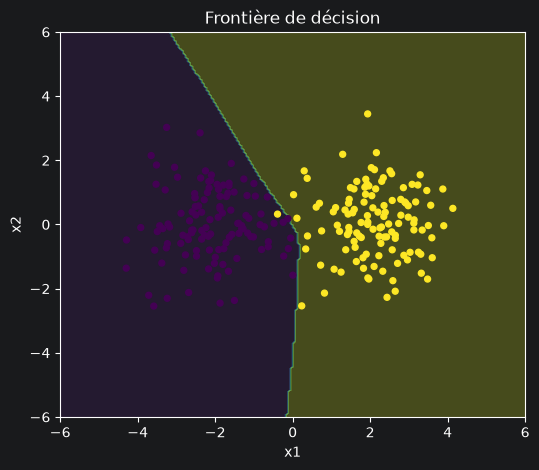

In [11]:
# Frontière de décision
g = torch.linspace(-6, 6, 200)
xx1, xx2 = torch.meshgrid(g, g, indexing="ij")
grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1).to(device)

with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape).cpu()

plt.figure(figsize=(6, 5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("Frontière de décision")
plt.show()